# Predicting Secondary Protein Structure Using a Convolutional Neural Network 
**Luca Wolfs - 7962258**

Introduction to Bioinformatics for Life Sciences  
RCSB-PDB annotated protein sequences  
Academic Year: 2026-2027  
Date: 22-10-2026  




### Abstract
Predicting secondary protein structure based on the amino acid sequence has a long history in bioinformatics. To gain insight into how these predictions work, I used a simple convolutional neural network that considers neighbouring amino acids to predict secondary protein structure in three classes: alpha-helix (H), beta-strand (E) and other structures (C). I trained the model on a curated subset from the RCSB-PDB and was able to reach an accuracy of 68%. The subsequently created confusion matrix suggested that alpha-helices were predicted better than beta-strands, although the lack of normalisation in the matrix made it difficult to draw more definitive conclusions. Apart from the lack of normalisation, the lack of hyperparameter tuning and small dataset likely played a role in the relatively low accuracy score. Overall, the results suggests that a simple neural network that considers neighbouring amino acids is able to predict the structural annotation of individual amino acids. 

### Introduction

Proteins are one of the building blocks of cells and execute most of their functions (Alberts et al., 2019). They are some of the most complex molecules around, with their three-dimensional structure being determined and stabilised by covalent and non-covalent bonds (Alberts et al., 2019). Gaining an understanding of the structure may be very informative, as it is important for their function, and many attempts have been made to predict the structure. One of the first approaches was homology modelling, which made use of the structure of proteins being more conserved than their sequence, letting proteins be modelled based on a homologous protein with a known structure (Ye et al., 2007). Today, it is hard to talk about protein structure prediction without mentioning AlphaFold, a neural network based model for predicting the full three-dimensional protein structure (Jumper et al., 2021).  

In this mini-project, I will attempt to predict secondary protein structure based on the underlying amino acid sequence, albeit in a much simpler manner and on a much smaller scale. To do this, I will make use of three different structural annotations. These annotations classify amino acids as being part of alpha-helices (H), beta-strands and bridges (E), and coils (C) including loops, turns and all other elements. For this project, I  make use of a dataset containing a subset of protein data with their respective structural annotations from the Research Collaboratory for Structural Bioinformatics Protein Data Bank, that has been filtered using the Protein Sequence Culling Server (% identity cutoff: 25%, resolution cutoff: 2Å, R-factor cutoff: 0.25), available from this URL: https://www.kaggle.com/datasets/alfrandom/protein-secondary-structure/data. Models using these three letter codes to annotate structure have been successful in the past, with accuracy over 80% (Montgomerie et al., 2006). Amino acids differ in their preference for certain structures and neighbouring amino acids (Xia & Xie, 2002), so a model that can use this information may be useful. To this end, I will use a small convolutional neural network, which should be able to consider local neighbouring amino acids when predicting the structural annotation of each amino acid. Using this model, I will then investigate to what extent it is able to predict secondary protein structure in terms of overall and class-specific accuracy. 



### Methods & Results
#### Inspecting and Preparing Data 
To create the convolutional neural netwerk, a dataset on which it can be trained is necessary. First, the required libraries are imported, after which the data is inspected.

In [5]:
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.image as mpimg
import requests
import numpy as np
from sklearn.model_selection import train_test_split
import json
import torch
import torch.nn as nn
import torch.optim as optim
from torch.utils.data import TensorDataset, DataLoader
from sklearn.metrics import classification_report, confusion_matrix
import seaborn as sns

Having imported the relevant packages, the data can be loaded in, keeping only the relevant columns.

In [13]:
cols = ["pdb_id", "chain_code", "seq", "sst3", "len", "has_nonstd_aa"] # Columns to use
df_peptides = pd.read_csv("./2018-06-06-pdb-intersect-pisces.csv", usecols = cols)
df_peptides.head(5)

,pdb_id,chain_code,seq,sst3,len,has_nonstd_aa
0,1FV1,F,NPVVHFFKNIVTPRTPPPSQ,CCCCCECCCCCCCCCCCCCC,20,False
1,1LM8,H,DLDLEMLAPYIPMDDDFQLR,CCCCCCCCCECCCCCCEECC,20,False
2,1O06,A,EEDPDLKAAIQESLREAEEA,CCCHHHHHHHHHHHHHHHCC,20,False
3,1QOW,D,CTFTLPGGGGVCTLTSECI*,CCCCCCCCCCCCCCCCCCCC,20,True
4,1RDQ,I,TTYADFIASGRTGRRNAIHD,CHHHHHHCCCCCCCCCCEEC,20,False


Inspecting the dataframe, there is an ID and chain code, which together show the origin of the amino acid sequence. Apart from that, the structural annotation and length of each sequence is present. Lastly, there is a column showing if the sequence has any amino acids in its sequence that are not standard (such as in sequence four). In this project, I will not remove them, however. 

After having investigated the data in the dataframe a bit, I will investigate it further. I will look at the length of the dataframe, the type of data in each column, and if any NAs are present. Lastly, I will check if each column contains a unique combination of ID and chain code.

In [17]:
print("Our dataframe contains",len(df_peptides),"rows.\n\nAdditionally, each column has the following data type:\n")
print(df_peptides.dtypes,"\n\nLastly, we check if there are any missing values:\n")
print("Occurance of any NAs:", df_peptides.isna().any().any()) # Checks if cells are NA, then if column has NA, then if any of the columns have NA.
print("Unique protein sequences:",  len(df_peptides[["pdb_id", "chain_code"]].drop_duplicates())) # Only keeps rows with unique combination, then looks at length. 

Our dataframe contains 9078 rows.

Additionally, each column has the following data type:

pdb_id           object
chain_code       object
seq              object
sst3             object
len               int64
has_nonstd_aa      bool
dtype: object 

Lastly, we check if there are any missing values:

Occurance of any NAs: False
Unique protein sequences: 9078


Investigating this information, the dataframe contains 9078 unique sequences, and all cells contain data.

Now, I will investigate the length of the sequences in the dataframe.

Summary statistics for the length of the amino acid sequences in our data:
 count    9078.000000
mean      243.168539
std       156.566596
min        20.000000
25%       132.000000
50%       208.000000
75%       323.000000
max      1632.000000


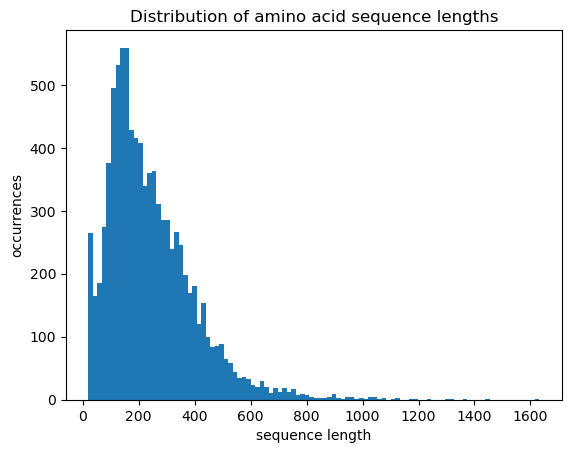

In [21]:
print("Summary statistics for the length of the amino acid sequences in our data:\n",df_peptides["len"].describe().to_string()) # .to_string to remove unnecessary information
plt.hist(df_peptides["len"], bins=100)
plt.title("Distribution of amino acid sequence lengths")
plt.xlabel("sequence length")
plt.ylabel("occurrences")
plt.show()

Looking at the output, the average number of amino acids in our sequences seems to be around 243, with a skew towards the right. This is expected, as the sequences cannot go lower than the minimal length of 20. Additionally, the maximum length of a sequence is 1632, showing the large variety in length of amino acid sequences in the dataframe.



Apart from this, it is a good idea to clarify the occurance of each of the three structural annotations in the dataset.

In [23]:
characters = df_peptides["sst3"].str.upper().apply(list) # Create a list of all structural annotation sequences
characters_counts = characters.explode().value_counts() # separates all characters to individual letters, then counts occurrences
print("The count for each of each possible structural annotation is\n",characters_counts.to_string()) 

The count for each of each possible structural annotation is
 C    938709
H    779825
E    488950


"C" seems most commonly present in the data. This makes sense, as it encompasses all structures that are not helices or beta-strands/bridges. Additionally, in this dataset, helices "H" are more common than beta-strands and sheets "E" (alpha-helices are the most common secondary structure).

After having investigated some fundamental aspects of the data, I investigated which organisms are represented in our dataset. I did this by utilising the IDs and chain codes present for each sequence. **As this code takes quite some time to run (we perform several API requests per sequence), the final result is already shown using a previously created file.**

In [ ]:
dict_orgs_={}
unknown_entity_IDs = 0

for i in range(0, len(df_peptides)): # Go over all sequences
    PDB_ID = df_peptides.iloc[i]["pdb_id"] # Retrieve PDB ID
    chain_code = df_peptides.iloc[i]["chain_code"] # Retrieve Chain code.
    
    url = f"https://data.rcsb.org/rest/v1/core/entry/{PDB_ID}" # Create url for API request, using the retrieved PDB ID.

    response = requests.get(url, timeout=15) # Request data from RCSB PDB database.
    if response.status_code == 404: #Check if code ran into 404 error, and move on if so. 
        unknown_entity_IDs += 1
        continue     
    data = response.json() # Parses response into a python object.

    # PDB IDs are not always specific to one amino acid chain, as one entry can have multiple sequences. 
    # Therefore, I need to check if there are multiple and choose the correct one via the chain code.
    entity_ids = data["rcsb_entry_container_identifiers"]["polymer_entity_ids"] # Retrieve column with entity IDs (so basically all sequences corresponding to the same PDB ID).
    
    entity_id = None
    for ent_ID in entity_ids: # Loop over all IDs until we find the one that corresponds with our chain ID, then extract the organism name.
        
        entity_url = f"https://data.rcsb.org/rest/v1/core/polymer_entity/{PDB_ID}/{ent_ID}" # Create url for API request, using PDB ID and entity ID.
        entity_response = requests.get(entity_url,timeout=15) # Request data for specific sequence (with our PDB ID), not all sequences with the same ID.
        if entity_response.status_code == 404: 
            unknown_entity_IDs += 1
            continue     
        entity_data = entity_response.json()

        identifiers = entity_data["rcsb_polymer_entity_container_identifiers"] # Retrieve dictionary with identifiers for specific entry.
        chain_ids = identifiers["auth_asym_ids"] # Find ID letters corresponding to our chain codes.
        
        if chain_code in chain_ids: 
            entity_id = ent_ID
            break # Go on when chain code matches to the code in the data.

    if entity_id is None:
        unknown_entity_IDs+=1
        continue

    organism = None
    for name in entity_data.get("rcsb_entity_source_organism",[]): # Look at dictionary containing naming information for the "entity_data" file we used to check if chain code matches this specific entry. 
        organism = name.get("ncbi_scientific_name") or name.get("scientific_name") # Retrieve the name of the organism. 
        if organism: # This checks whether organism is True (non-empty string) or False (empty). 
            break 
    else: 
            organism = "missing_orgs" # If there is no organism name, file as missing. 
            
    if organism in dict_orgs_: # Add the name of the organism to dictionary, count how often organism name is present.
        dict_orgs_[organism]+=1
    else:
        dict_orgs_[organism]=1

In [4]:
with open('final_dict_orgs.json', 'r', encoding='utf-8') as file:
    final_dict_orgs = json.load(file)
    
print("The ten most common species in our dataset are:",list(final_dict_orgs.items())[:10])

The ten most common species in our dataset are: [('Homo sapiens', 2084), ('Escherichia coli', 402), ('Mus musculus', 372), ('Saccharomyces cerevisiae', 248), ('Escherichia coli K-12', 212), ('Arabidopsis thaliana', 158), ('Bacillus subtilis', 144), ('Saccharomyces cerevisiae S288C', 142), ('Drosophila melanogaster', 134), ('Pseudomonas aeruginosa PAO1', 118)]


Looking at the resulting dictionary, clearly, human proteins are represented the most. This overrepressentation of humans likely stems from the focus on mainly human research. Still, other interesting organisms are represented, such as other animals, yeasts, bacteria and plants. The dataframe contains a set of proteins from many different organisms. 

#### Analysing the Data: Creating and Training the Neural Network
After having investigated the data, it was time to create and train the neural network model. To do this, first, the data haad been split into a training, validation and test set in a ratio of 0.7 : 0.15 : 0.15

In [29]:
train_val_df, test_df = train_test_split(df_peptides, test_size=0.15, random_state=42) # First, we split our data into training+validation and test data.

train_df, val_df = train_test_split(train_val_df, test_size=0.1765, random_state=42) # Then, we split the combined training and validation data into separate dataframes.

print(f"Training DataFrame:   {len(train_df)} rows")
print(f"Validation DataFrame: {len(val_df)} rows")
print(f"Testing DataFrame:    {len(test_df)} rows")

Training DataFrame:   6354 rows
Validation DataFrame: 1362 rows
Testing DataFrame:    1362 rows


After having created the datasets, the amino acid one letter codes and structural annotations had to be converted into integers, to make sure the model is able to work with them.

In [30]:
aminoacids="ACDEFGHIKLMNPQRSTVWY*"
structure_annotate="CEH"

aa_encoding={}
str_encoding={}
for index_aa, aminoacid in enumerate(aminoacids): # Enumerate gives both the index and one letter code. 
    aa_encoding[aminoacid]=index_aa # Create a dictionary with one letter code and corresponding integer
for index_str, annotation in enumerate(structure_annotate): 
    str_encoding[annotation]=index_str

Having converted the one letter codes into integers, the integers needed to be converted into binary arrays for the model to understand (one-hot encoding). 

In [35]:
def one_hot_encode(sequence, index): # We create a function that takes a sequence and the integer code for amino acids.
    indices=[]
    for aa in sequence: # Go over all one letter codes in a sequence
        indices.append(index[aa]) # Add the corresponding integer for each one letter code.
    indices = np.array(indices) # Convert list with integers to array, needed for follow up.

    encoded = np.zeros((len(sequence), len(index)), dtype=np.float32) # Create a blank matrix, the length of the sequence and the width of the index (number of letters/integers).
    encoded[np.arange(len(sequence)), indices] = 1 # Now, we add a 1 to the column that represents our amino acid/structural annotation.  

    return encoded

# Example result for amino acids (but this works with any number of one letter codes)
example_seq = train_df["seq"].iloc[0]
encoded_seq = one_hot_encode(example_seq, aa_encoding)
print(encoded_seq[:5])

[[0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0.]
 [0. 0. 0. 0. 0. 0. 1. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0. 0.]]


The example here shows the first five amino acids, encoded as a binary array, where the column in which the 1 is in corresponds to the amino acid. If multiple sequences were given, then the function would also return multiple arrays.

After having made sure that the data can be given to the model, the data should be divided into 'windows'. This is done to give the model context of what amino acids surround each other, and keeps the following steps simple.

In [33]:
def create_windows(aa_arrays, structure_arrays, window_size=15): # Create function asking for both arrays we created, and a window size.
    pad_number = window_size // 2 # As first and last amino acids will not have neighbours on one side, we pad those windows with blanks.
    aa_window_list = []
    str_target_list =[]
    
    for aa_array, structure_array in zip(aa_arrays,structure_arrays): # Loop over each amino acid sequence and respective structural annotation sequence. 
        seq_length = len(aa_array) 
        padding = np.zeros((pad_number,aa_array.shape[1])) # Create blank array, of "pad_number" rows and aa_array.shape[1] columns .
        padded_aa_array = np.vstack([padding,aa_array ,padding]) # Create new array by adding the padded edges.
        
        for aa in range(0,seq_length): #Now, go over each amino acid within the array.
            slice_peptide = padded_aa_array[aa:aa+window_size] # Get a window for the amino acid, this starts at the first amino acid (as that is now in the middle)
            specifics_str_array = structure_array[aa] # Get the structural annotation row for the amino acid.
            aa_window_list.append(slice_peptide) # Append window to list of windows
            str_target_list.append(specifics_str_array)
            
    return np.array(aa_window_list,dtype=np.float32), np.array(str_target_list,dtype=np.float32) # Return the lists as arrays.

After creating the windows for the amino acids, the convolutional model could be created and defined. As the project was limited in time, not too much time could be spent on potential optimisation and hyperparameters were not refined. 

In [34]:
class proteinCNN(nn.Module): # Create a python object called proteinCNN with the nn.Module inheritance that brings many complex blueprints (thank you meta engineers) 
    def __init__(self, num_classes=3): # This instantiates the trainable layers and configurations, function runs only once.
        
        super(proteinCNN, self).__init__() # Initialises the nn.Module.
        self.conv1 = nn.Conv1d(in_channels=21, out_channels=32, kernel_size=7) # Define convolution step, tells model the number of values, number of patterns, and width of kernel. 
        self.relu = nn.ReLU() # Change all negative predictions to 0.0
        self.fc = nn.Linear(32 * 9, num_classes)  #  32 output parameters * 9 degrees of freedom (window size of 15 - 7 kernel size), produce num_classes number of scores.
       
    def forward(self, x): # Defines step-by-step how data should flow, function runs every time. 
        
        x = x.transpose(1, 2) # Flip second and third dimension of data, (model expects batch size, channels, length).
        x = self.conv1(x) # Scan the sequence, look for patterns, this is the convolutional layer.
        x = self.relu(x) # Erase negative values from feature maps (into 0.0).
        x = torch.flatten(x, start_dim=1) # 32 feature maps with 9 values each are flattened to one vector.
        
        x = self.fc(x) # Compress the  32 features into  3  structural annotation outputs, fully connected layer, 
        
        return x

After defining the model, it still needed to be trained. To do this, I combined everyhing I have built beforehand. As mentioned before, there was no time for refinement of hyperparameters. As a result, I decided on using only three epochs. I did print out the scores each epoch had, to evaluate if the model was 'learning'.
**There is no need to run the cell underneath this text; the model parameters have been saved in a different file already**.

In [36]:
# === Creating data that will be used by model ===
# Training set
AA_encoded_training = [one_hot_encode(seq, aa_encoding) for seq in train_df["seq"]] # Create the binarised arrays.
STR_encoded_training = [one_hot_encode(sst3, str_encoding) for sst3 in train_df["sst3"]]
x_data, y_data = create_windows(AA_encoded_training,STR_encoded_training,window_size=15) # Create the windows per amino acids.
# We transform the ENTIRE dataset here into tensors.
all_X_tensor = torch.tensor(x_data, dtype=torch.float32) # Transform data into specialised tensor array.
all_y_tensor = torch.tensor(np.argmax(y_data, axis=1), dtype=torch.long)
train_dataset = TensorDataset(all_X_tensor, all_y_tensor) 

train_loader = DataLoader(train_dataset, batch_size=32, shuffle=True) # Our full dataset is too large to load into memory at once, so we create batches (32 windows at once). These are randomised in each epoch with shuffle = True.

# Validation set
AA_encoded_val = [one_hot_encode(seq, aa_encoding) for seq in val_df["seq"]]
STR_encoded_val = [one_hot_encode(sst3, str_encoding) for sst3 in val_df["sst3"]]
x_data_val, y_data_val = create_windows(AA_encoded_val,STR_encoded_val,window_size=15)

val_X_tensor = torch.tensor(x_data_val, dtype=torch.float32)
val_y_tensor = torch.tensor(np.argmax(y_data_val, axis=1), dtype=torch.long)
val_dataset = TensorDataset(val_X_tensor, val_y_tensor)

val_loader = DataLoader(val_dataset, batch_size=32, shuffle=False) # does not need to be be shuffled as no training is done on validation data.

# === Creating model and training it ===

new_model = proteinCNN(num_classes=3) 
criterion = nn.CrossEntropyLoss() # Define a loss function that 'grades' preditions of the model
optimizer = optim.Adam(new_model.parameters(), lr=0.001) # Define optimiser that will optimise parameters of model.

epochs = 3 # Go through training set three times.

print("--- Starting Training Run ---")
for epoch in range(epochs):
    
    new_model.train() # Training model
    epoch_train_loss = 0.0
    
    for batch_X, batch_y in train_loader: # Give batches one at a time. 
        optimizer.zero_grad()
        predictions = new_model(batch_X) # Let model predict based on amino acid sequence.
        loss = criterion(predictions, batch_y) # Calculate scores of predictions
        loss.backward()
        optimizer.step() # Optimise parameters 
        epoch_train_loss += loss.item()
        
   
    new_model.eval() # Model validation, after round of training, in evaluation mode.
    epoch_val_loss = 0.0
    
    with torch.no_grad():
        for batch_X, batch_y in val_loader: 
            val_predictions = new_model(batch_X) # Let model predict validation sequences.
            val_loss = criterion(val_predictions, batch_y) # Score predictions
            epoch_val_loss += val_loss.item()
            
    avg_train_loss = epoch_train_loss / len(train_loader) # Calculate average training grade across batches
    avg_val_loss = epoch_val_loss / len(val_loader)  # Calculate average grade across validation batches
    
    print(f"Epoch {epoch}  Train Loss: {avg_train_loss:.4f}  Val Loss: {avg_val_loss:.4f}")

--- Starting Training Run ---
Epoch 0  Train Loss: 0.7478  Val Loss: 0.7374
Epoch 1  Train Loss: 0.7311  Val Loss: 0.7346
Epoch 2  Train Loss: 0.7277  Val Loss: 0.7338


The loss scores for the training and validation set do not seem to go down much after the second epoch (named epoch 1 above). Most likely, this means that the model found most of the relevant information in the first and second epoch. While it is possible that more epochs would lead to lower scores, this would increase the risk of overfitting and increases the time it takes to run the model. Additionally, a low validation loss score does not necessarily equate to a high accuracy (as loss scores are continous while accuracy only looks at right or wrong). 

#### Testing and Evaluating the Neural Network
With the model being trained, it was time to test its predictive capabilities using the test data set. To evaluate the accuracy of our model, an accuracy score was calculated that divided the number of correct predictions by the total number of predictions. **This code can take a couple of minutes to run. Instead of running it, the cell below prints the accuracy score from a file**.

In [83]:
# Test set
AA_encoded_test = [one_hot_encode(seq, aa_encoding) for seq in test_df["seq"]]
STR_encoded_test = [one_hot_encode(sst3, str_encoding) for sst3 in test_df["sst3"]]
x_data_test, y_data_test = create_windows(AA_encoded_test, STR_encoded_test, window_size=15)

X_test_tensor = torch.tensor(x_data_test, dtype=torch.float32)
y_test_true = np.argmax(y_data_test, axis=1) # The answer key

new_model = proteinCNN()
new_model.load_state_dict(
    torch.load("protein_cnn_32x7.pth", weights_only=True)) # Give model parameters from trained model.
new_model.eval() # Switch model to evaluation.

with torch.no_grad():
    test_outputs = new_model(X_test_tensor) # No batches this time
    test_predictions = torch.argmax(test_outputs, dim=1).numpy() # Pick highest scores as prediction for each position, as we want only one.

correct_predictions = np.sum(test_predictions == y_test_true) # Count the number of correct predictions
accuracy = (correct_predictions / len(y_test_true)) * 100 # Calculate accuracy score by dividing correct predictions by total. 

with open("test_results.txt", "w") as file_accuracy_score: # Write results to a text file. 
    file_accuracy_score.write(f"Total Test Amino Acids Evaluated: {len(y_test_true)}\n")
    file_accuracy_score.write(f"Accuracy Score: {accuracy:.2f}%\n")

Total Test Amino Acids Evaluated: 336204
Accuracy Score:       68.13%


In [150]:
with open("test_results.txt", 'r') as file_test:
    print(file_test.read())

Total Test Amino Acids Evaluated: 336204
Accuracy Score: 68.13%



The models accuracy score is 68.13% across 336.204 evaluated amino acids. While that is not very high, it is good to keep in mind this is a simple model with not much data. It is, however, clearly higher than if it were to guess at random, as this would come out to a score of around 33.34 %, as there are three classes. 

While the accuracy score tells us how well a model did, a confusion matrix can be created that shows how well the model predicted each class of structural annotation. This matrix compares the prediction versus the true annotations. 

In [156]:
str_classes = ["C", "E", "H"]
cm = confusion_matrix(y_test_true, test_predictions, labels=list(range(len(str_classes)))) # Create confusion matrix using the prediction results.

plt.figure(figsize=(8,6)) # Give dimensions for figure. 
plt.title("Predicted Secondary Protein Structure Versus Actual")
sns.heatmap(cm, annot = True, fmt= "d", cmap = "crest", xticklabels = str_classes, yticklabels = str_classes, annot_kws={"color": "white"}) 

plt.xlabel('Predicted structure annotation', fontsize=12)
plt.ylabel('True structure annotation', fontsize=12)
plt.savefig("conf_matrix_MiniProject.png") # Save figure as a file. 
plt.close()

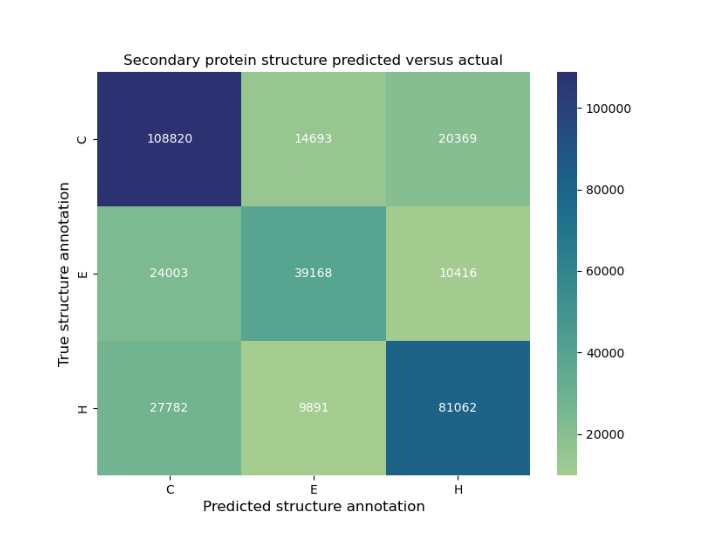

In [3]:
img = mpimg.imread('conf_matrix_MiniProject.png')
plt.figure(figsize=(9, 7))
plt.axis('off')
plt.imshow(img)
plt.show()

This figure compares the number of times the model predicted a certain structural annotation (columns) with the true annotations (rows). Using this, it is possible to infer which predictions the model struggled with, and which annotations it was able to predict more reliably. What seems apparent from this figure, is that the model most often guessed "C". This corresponds relatively well with the true counts, as C is the most numerous annotation in the dataset. The model did, however, also predict a lot of H and E annotations to C, suggesting the model may overpredict "C"s somewhat. Calculating this, the predicted versus true share of "C" was 47.7% versus 42.7% respectively, showing that it does not overpredict "C" by a large margin.

Focussing on the H and E annotations, the model seems to predict alpha-helices somewhat accurately. The model performs less well for beta-strands, where the model more often seems to classify them as "C", or classifies "C"s as "E". Interestingly, the model seems to differentiate alpha-helices and beta-strands quite nicely. Due to the lack of time, no normalisation of the numbers in the confusion matrix was performed, however, limiting any conclusions that can be drawn from the matrix.

### Conclusion
I aimed to test how well a simple convolutional neural network was able to predict structural annotations of amino acids. It was able to predict this to an accuracy of 68%. The model seemed to be able to separate alpha-helices and beta-strands, and was able to predict helices relatively well. It did, however, not seem to perform well for predicing "E"s accurately. As the model predicted only three structural annotations, however, it is impossible to say if the model struggles with differentiating certain structures that are now hidden in the “C” category with the other annotations. Still,the results show that a simple neural network with information to neighbouring amino acids is able to predict protein structure to at least some level.


### Discussion

Having discussed protein structure prediction throughout the Introduction to Bioinformatics in Life Sciences course, I aimed to gain a better understanding of what this actually looks like in a simplified form. I feel that what I mainly improved as a result of this project, is the understanding of the steps and software behind pipelines to process data. Especially the preparation of the data, which took most of my time, showed me how important this step is. Interestingly, the model seems to perform worse for beta-strands compared to alpha-helices. While this may be due to a lower number of beta-strands in the data, it also makes biological sense. Alpha-helices interact heavily with nearby amino acids, while beta-strands interact with amino acids far away in the amino acid sequence. The model could therefore have a more difficult time with predicting beta-strands.

Due to the limited time, the neural network has some limitations. First, I chose a single set of hyperparameters instead of testing which one fit best. This can lead to the model performing worse than it otherwise would, reducing the prediction accuracy. Additionally, the model was trained using a relatively small dataset, likely further reducing the prediction accuracy. Apart from that, I was not able to normalise the counts in the confusion matrix, making it more difficult to clearly draw conclusions from it. Still, the results suggest that the model is at least somewhat able to predict structural annotations of proteins based on their amino acid sequence, given the accuracy of 68%. This accuracy, combined with the fact that it would be around 43% if it were to just always predict the most common structural annotation, or 33.34% if it were to guess at random, gives me some confidence that the model is able to predict structural annotations of amino acids.

If I had more time, I would first normalise the values in the confusion matrix to more clearly report the predictions for each class of annotation and investigate if the model really struggles with beta-strands more than the other annotations. Secondly, I would tune the hyperparameters to improve the model's predictions. Lastly, I would want to examine the predictions the model made to see if there is a patterns in where the predictions fail and where they are most accurate, as I feel this could help me optimise the model further. Overall, this neural network was not created to compete against models with far more input data, parameters and computational power behind them. Instead, it allowed me to increase my understanding of how protein structure is predicted, and how to approach such a broad question and create a functional pipeline based on it. 




### AI-use Disclosure
ChatGPT (GPT-5.6 Luna) was used as a supplementary tool during the development of this mini-project. Its contributions are summarised below using the CRediT-based roles.

| Role | Contribution | Specific contribution |
|---|---|---|
| Conceptualisation | No | The research question and project focus were established independently. An alternative research question discussed with ChatGPT was not adopted. |
| Methodology | Yes | ChatGPT explained the relationship between the sequence window and convolutional kernel, how local sequence context is used to predict a residue's secondary-structure annotation, and how the chosen CNN architecture processes its input. The choice of a 1D CNN was made independently after researching commonly used methods. |
| Software | Yes | ChatGPT explained parts of the PyTorch implementation, including `nn.Conv1d`, `ReLU`, `torch.max`, `torch.flatten`, and `nn.Linear`. It suggested some code and helped troubleshoot the fully connected layer's input dimensions and a plotting-code error. Other code was obtained from online sources. The implementation was developed by the author; ChatGPT did not execute the notebook. |
| Formal Analysis | Yes (limited) | ChatGPT provided explanations and sanity checks for analytical outputs supplied by the author, including test accuracy and the confusion matrix. It also explained additional classification metrics that were not included in the final analysis. ChatGPT did not run the analysis, calculate the final results, or independently verify them. |
| Data Curation | No | The dataset was obtained from Kaggle, and data preparation was performed independently without ChatGPT assistance. |
| Visualisation | No | The final confusion-matrix visualisation was developed independently, using the author's own approach and external resources. Suggestions from ChatGPT were not adopted for the final figure. |
| Validation | Yes (limited) | ChatGPT helped check the author's understanding of the code and model implementation, including tensor dimensions, layer output shapes, and training and validation losses. This did not constitute systematic testing or independent verification of the final results. |
| Writing – original draft | No | The report was written independently by the author without AI-generated wording. |
| Writing – review & editing | No | ChatGPT was not used to review or edit the written report. |

ChatGPT's role was primarily explanatory and supportive. The author made the project decisions, prepared the data, developed the final visualisation, performed the analysis, and wrote the report. 

### Literature
Bruce Alberts, Rebecca Heald, Karen Hopkin, Alexander Johnson, David Morgan, Keith Roberts, & Peter Walter. (2019). Protein Structure and Function. Essential Cell Biology (fifth edition). W.W. Norton & Company.

Jumper, J., Evans, R., Pritzel, A., Green, T., Figurnov, M., Ronneberger, O., Tunyasuvunakool, K., Bates, R., Žídek, A., Potapenko, A., Bridgland, A., Meyer, C., Kohl, S. A. A., Ballard, A. J., Cowie, A., Romera-Paredes, B., Nikolov, S., Jain, R., Adler, J., … Hassabis, D. (2021). Highly accurate protein structure prediction with AlphaFold. Nature, 596(7873), 583–589. https://doi.org/10.1038/s41586-021-03819-2

Montgomerie, S., Sundararaj, S., Gallin, W. J., & Wishart, D. S. (2006). Improving the accuracy of protein secondary structure prediction using structural alignment. BMC Bioinformatics, 7, 301. https://doi.org/10.1186/1471-2105-7-301

Wooley, J. C., & Ye, Y. (2007). A Historical Perspective and Overview of Protein Structure Prediction. In Y. Xu, D. Xu, & J. Liang (Eds), Computational Methods for Protein Structure Prediction and Modeling: Volume 1: Basic Characterization (pp. 1–43). Springer. https://doi.org/10.1007/978-0-387-68372-0_1

Xia, X., & Xie, Z. (2002). Protein Structure, Neighbor Effect, and a New Index of Amino Acid Dissimilarities. Molecular Biology and Evolution, 19(1), 58–67. https://doi.org/10.1093/oxfordjournals.molbev.a003982
